In [1]:
from pathlib import Path
import json
import zipfile
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 120)
pd.set_option("display.width", 200)

ROOT = Path.cwd()

CAPACITY = 3456
HOURS_PER_EVAL = 168

REFERENCE_Q = 0.90
REFERENCE_H = 1
EVICTION_SLO = 0.10

OUT = ROOT / "outputs_fame_gpu_04c"
OUT.mkdir(exist_ok=True)

In [2]:
def locate_folder_or_zip(folder_name):
    for p in [
        ROOT/folder_name,
        Path("/mnt/data")/folder_name
    ]:
        if p.exists() and p.is_dir():
            return p

    for zp in [
        ROOT/f"{folder_name}.zip",
        Path("/mnt/data")/f"{folder_name}.zip"
    ]:
        if zp.exists():
            target = ROOT/f"{folder_name}_04c_extract"
            target.mkdir(exist_ok=True)

            with zipfile.ZipFile(zp) as z:
                z.extractall(target)

            p = target/folder_name

            if p.exists():
                return p

    raise FileNotFoundError(
        f"{folder_name}(.zip) não encontrado."
    )

OUT4B = locate_folder_or_zip(
    "outputs_fame_gpu_04b_v4"
)

surface = pd.read_csv(
    OUT4B/"CE_utility_surfaces.csv"
)

repro = pd.read_csv(
    OUT4B/"C_reproduction_check.csv"
)

roles = pd.read_csv(
    OUT4B/"replication_roles.csv"
)

old_summary = pd.read_csv(
    OUT4B/"frozen_transfer_summary.csv"
)

coverage = pd.read_csv(
    OUT4B/"transfer_coverage_check.csv"
)

print("OUT4B:", OUT4B)
print("Surface rows:", len(surface))
display(coverage)

OUT4B: c:\Users\tiago\Dropbox\Artigos\FAME\FAME\Artigo 2 - AOR\FAME_GPU\outputs_fame_gpu_04b_v4_04c_extract\outputs_fame_gpu_04b_v4
Surface rows: 90


,replication,n_candidates,expected,complete
0,R04,15,15,True
1,R05,15,15,True
2,R06,15,15,True
3,R07,15,15,True
4,R08,15,15,True
5,R09,15,15,True


In [3]:
required = {
    "replication","q","H","status",
    "C_allocation_rate","C_eviction_rate",
    "E_allocation_rate","E_eviction_rate",
    "U_C","U_E"
}

missing = required - set(surface.columns)

if missing:
    raise RuntimeError(
        "Colunas ausentes: " + ", ".join(sorted(missing))
    )

if not coverage["complete"].all():
    raise RuntimeError(
        "Cobertura incompleta: nem todas as replicações possuem 15 candidatos."
    )

if not (surface["status"]=="ok").all():
    raise RuntimeError(
        "Existem branches com status diferente de ok."
    )

print("[OK] Cobertura e schema completos.")

[OK] Cobertura e schema completos.


In [4]:
repro["allocation_error_gpu_hours"] = (
    repro["max_abs_allocation_error"]
    * CAPACITY
    * HOURS_PER_EVAL
)

display(repro)

repro.to_csv(
    OUT/"C_reproduction_discrepancy.csv",
    index=False
)

affected = repro[
    (
        repro["max_abs_allocation_error"] > 1e-10
    )
    |
    (
        repro["max_abs_eviction_error"] > 1e-10
    )
]["replication"].tolist()

print(
    "Replicações com diferença mensurável entre 04A e 04B:",
    affected
)

print(
    "\nDecisão metodológica: o 04A não será usado "
    "para selecionar phi_C na análise final."
)

,replication,max_abs_allocation_error,max_abs_eviction_error,n_candidates_checked,allocation_error_gpu_hours
0,R04,0.000000,0.000000,15,0.000000
1,R05,0.004642,0.000597,15,2695.150000
2,R06,0.000493,0.001339,15,286.000000
3,R07,0.000024,0.000311,15,13.866667
4,R08,0.002379,0.006828,15,1381.133333
5,R09,0.001951,0.002162,15,1132.666667


Replicações com diferença mensurável entre 04A e 04B: ['R05', 'R06', 'R07', 'R08', 'R09']

Decisão metodológica: o 04A não será usado para selecionar phi_C na análise final.


In [5]:
def select_candidate(g, period):
    a = f"{period}_allocation_rate"
    e = f"{period}_eviction_rate"

    feasible = g[g[e] <= EVICTION_SLO].copy()

    if len(feasible):
        feasible["ref_distance"] = (
            abs(feasible["q"] - REFERENCE_Q)
            + .05*abs(feasible["H"] - REFERENCE_H)
        )

        return (
            feasible
            .sort_values(
                [a,e,"ref_distance"],
                ascending=[False,True,True]
            )
            .iloc[0]
        )

    return (
        g.sort_values(
            [e,a],
            ascending=[True,False]
        )
        .iloc[0]
    )


selection_rows = []

for rep,g in surface.groupby("replication"):
    c = select_candidate(g,"C")

    selection_rows.append({
        "replication":rep,
        "phi_C_q":float(c["q"]),
        "phi_C_H":int(c["H"]),
        "C_allocation":float(c["C_allocation_rate"]),
        "C_eviction":float(c["C_eviction_rate"]),
        "U_C_selected":float(c["U_C"]),
    })

selection_C = pd.DataFrame(selection_rows)

display(selection_C)

selection_C.to_csv(
    OUT/"consistent_doc_selection_C.csv",
    index=False
)

,replication,phi_C_q,phi_C_H,C_allocation,C_eviction,U_C_selected
0,R04,0.90,1,0.752675,0.000000,0.752675
1,R05,0.90,4,0.903835,0.002190,0.903835
2,R06,0.80,4,0.923895,0.002695,0.923895
3,R07,0.90,4,0.785113,0.000308,0.785113
4,R08,0.95,2,0.857655,0.007838,0.857655
5,R09,0.99,4,0.920159,0.005938,0.920159


In [6]:
id_rows = []

for rep,g in surface.groupby("replication"):
    feasible = g[
        g["C_eviction_rate"] <= EVICTION_SLO
    ].copy()

    feasible["ref_distance"] = (
        abs(feasible["q"]-REFERENCE_Q)
        + .05*abs(feasible["H"]-REFERENCE_H)
    )

    s = feasible.sort_values(
        [
            "C_allocation_rate",
            "C_eviction_rate",
            "ref_distance"
        ],
        ascending=[False,True,True]
    ).reset_index(drop=True)

    best = s.iloc[0]
    second = s.iloc[1]

    gap = (
        best["C_allocation_rate"]
        - second["C_allocation_rate"]
    )

    range_alloc = (
        g["C_allocation_rate"].max()
        - g["C_allocation_rate"].min()
    )

    id_rows.append({
        "replication":rep,
        "best_q":float(best["q"]),
        "best_H":int(best["H"]),
        "top_gap_allocation":float(gap),
        "top_gap_GPU_hours":float(
            gap*CAPACITY*HOURS_PER_EVAL
        ),
        "surface_range_allocation":float(range_alloc),
        "surface_range_GPU_hours":float(
            range_alloc*CAPACITY*HOURS_PER_EVAL
        ),
        "eviction_surface_range":float(
            g["C_eviction_rate"].max()
            - g["C_eviction_rate"].min()
        ),
        "flat_surface":bool(
            range_alloc < 1e-10
            and (
                g["C_eviction_rate"].max()
                - g["C_eviction_rate"].min()
            ) < 1e-10
        ),
    })

identification = pd.DataFrame(id_rows)

display(identification)

identification.to_csv(
    OUT/"consistent_calibration_identification.csv",
    index=False
)

,replication,best_q,best_H,top_gap_allocation,top_gap_GPU_hours,surface_range_allocation,surface_range_GPU_hours,eviction_surface_range,flat_surface
0,R04,0.90,1,0.000000,0.000000,0.000000,0.000000,0.000000,True
1,R05,0.90,4,0.000577,335.133333,0.005862,3403.433333,0.001193,False
2,R06,0.80,4,0.000050,28.783333,0.011088,6437.566667,0.006751,False
3,R07,0.90,4,0.000002,1.116667,0.001111,645.316667,0.003434,False
4,R08,0.95,2,0.000088,51.183333,0.008057,4678.216667,0.011913,False
5,R09,0.99,4,0.000117,68.200000,0.003116,1809.000000,0.016107,False


In [7]:
summary_rows = []

for rep,g in surface.groupby("replication"):
    c_sel = selection_C[
        selection_C["replication"]==rep
    ].iloc[0]

    frozen = g[
        np.isclose(g["q"],c_sel["phi_C_q"])
        & (g["H"]==c_sel["phi_C_H"])
    ].iloc[0]

    ref = g[
        np.isclose(g["q"],REFERENCE_Q)
        & (g["H"]==REFERENCE_H)
    ].iloc[0]

    oracle = select_candidate(g,"E")

    rank_df = g.sort_values(
        ["U_E","E_eviction_rate"],
        ascending=[False,True]
    ).reset_index(drop=True)

    match = rank_df[
        np.isclose(rank_df["q"],frozen["q"])
        & (rank_df["H"]==frozen["H"])
    ]

    rank_E = int(match.index[0]+1)

    raw_shift = float(
        np.max(
            np.abs(
                g["U_C"].to_numpy()
                - g["U_E"].to_numpy()
            )
        )
    )

    dC = (
        g["U_C"].to_numpy()
        - float(ref["U_C"])
    )

    dE = (
        g["U_E"].to_numpy()
        - float(ref["U_E"])
    )

    centered_shift = float(
        np.max(np.abs(dC-dE))
    )

    summary_rows.append({
        "replication":rep,

        "phi_C_q":float(frozen["q"]),
        "phi_C_H":int(frozen["H"]),

        "phi_E_oracle_q":float(oracle["q"]),
        "phi_E_oracle_H":int(oracle["H"]),

        "U_C_selected":float(frozen["U_C"]),
        "U_E_frozen":float(frozen["U_E"]),
        "U_E_reference":float(ref["U_E"]),
        "U_E_oracle":float(oracle["U_E"]),

        "gain_vs_reference":float(
            frozen["U_E"]-ref["U_E"]
        ),

        "transfer_regret":float(
            oracle["U_E"]-frozen["U_E"]
        ),

        "gain_vs_reference_GPU_hours":float(
            (
                frozen["U_E"]-ref["U_E"]
            )
            * CAPACITY
            * HOURS_PER_EVAL
        ),

        "transfer_regret_GPU_hours":float(
            (
                oracle["U_E"]-frozen["U_E"]
            )
            * CAPACITY
            * HOURS_PER_EVAL
        ),

        "frozen_rank_in_E":rank_E,

        "frozen_E_allocation":float(
            frozen["E_allocation_rate"]
        ),

        "frozen_E_eviction":float(
            frozen["E_eviction_rate"]
        ),

        "reference_E_allocation":float(
            ref["E_allocation_rate"]
        ),

        "reference_E_eviction":float(
            ref["E_eviction_rate"]
        ),

        "representation_shift_hat":raw_shift,
        "centered_representation_shift_ref":centered_shift,

        "mean_abs_surface_shift":float(
            np.mean(
                np.abs(
                    g["U_C"].to_numpy()
                    - g["U_E"].to_numpy()
                )
            )
        ),

        "argmax_changed":bool(
            not (
                np.isclose(
                    frozen["q"],
                    oracle["q"]
                )
                and int(frozen["H"])==int(oracle["H"])
            )
        ),
    })

summary = pd.DataFrame(summary_rows)

predictive_cols = old_summary[
    [
        "replication",
        "delta_RMSE_pct",
        "delta_MAE_pct"
    ]
].drop_duplicates()

summary = summary.merge(
    predictive_cols,
    on="replication",
    how="left"
)

summary = summary.merge(
    roles,
    on="replication",
    how="left"
)

summary = summary.merge(
    identification[
        [
            "replication",
            "top_gap_GPU_hours",
            "surface_range_GPU_hours",
            "flat_surface"
        ]
    ],
    on="replication",
    how="left"
)

display(summary)

summary.to_csv(
    OUT/"consistent_frozen_transfer_summary.csv",
    index=False
)

,replication,phi_C_q,phi_C_H,phi_E_oracle_q,phi_E_oracle_H,U_C_selected,U_E_frozen,U_E_reference,U_E_oracle,gain_vs_reference,transfer_regret,gain_vs_reference_GPU_hours,transfer_regret_GPU_hours,frozen_rank_in_E,frozen_E_allocation,frozen_E_eviction,reference_E_allocation,reference_E_eviction,representation_shift_hat,centered_representation_shift_ref,mean_abs_surface_shift,argmax_changed,delta_RMSE_pct,delta_MAE_pct,role,top_gap_GPU_hours,surface_range_GPU_hours,flat_surface
0,R04,0.90,1,0.99,4,0.752675,0.807490,0.807490,0.807561,0.000000,0.000071,0.000000,40.983333,9,0.807490,0.000000,0.807490,0.000000,0.054886,0.000071,0.054824,True,-12.953154,-0.785542,boundary_flat_C_surface,0.000000,0.000000,True
1,R05,0.90,4,0.99,1,0.903835,0.891234,0.892441,0.894420,-0.001207,0.003187,-700.666667,1850.150000,15,0.891234,0.002902,0.892441,0.001140,0.012601,0.005359,0.008905,True,-0.437502,1.890153,principal_transfer,335.133333,3403.433333,False
2,R06,0.80,4,0.99,4,0.923895,0.836255,0.835578,0.837602,0.000677,0.001347,392.866667,782.166667,7,0.836255,0.010957,0.835578,0.006708,0.088497,0.012746,0.086667,True,180.782571,164.730739,principal_transfer,28.783333,6437.566667,False
3,R07,0.90,4,0.80,2,0.785113,0.819209,0.819371,0.819639,-0.000162,0.000429,-94.083333,249.350000,6,0.819209,0.015832,0.819371,0.014180,0.034528,0.005153,0.033421,True,-6.885477,-0.160175,principal_transfer,1.116667,645.316667,False
4,R08,0.95,2,0.99,1,0.857655,0.894328,0.891467,0.900132,0.002861,0.005805,1660.866667,3370.350000,4,0.894328,0.003604,0.891467,0.003223,0.045088,0.038268,0.027728,True,12.980761,22.049966,principal_transfer,51.183333,4678.216667,False
5,R09,0.99,4,0.80,2,0.920159,0.885656,0.882135,0.890761,0.003521,0.005105,2044.316667,2964.283333,4,0.885656,0.013135,0.882135,0.017640,0.041777,0.009224,0.035927,True,21.220738,29.049832,principal_transfer,68.200000,1809.000000,False


In [8]:
principal = summary[
    summary["role"]=="principal_transfer"
].copy()

display(
    principal[
        [
            "replication",
            "phi_C_q","phi_C_H",
            "phi_E_oracle_q","phi_E_oracle_H",
            "delta_RMSE_pct",
            "representation_shift_hat",
            "centered_representation_shift_ref",
            "gain_vs_reference",
            "gain_vs_reference_GPU_hours",
            "transfer_regret",
            "transfer_regret_GPU_hours",
            "frozen_rank_in_E",
            "frozen_E_eviction",
            "argmax_changed",
        ]
    ]
)

aggregate = pd.Series({
    "n_principal":len(principal),

    "mean_gain_vs_reference":
        principal["gain_vs_reference"].mean(),

    "median_gain_vs_reference":
        principal["gain_vs_reference"].median(),

    "mean_gain_vs_reference_GPU_hours":
        principal["gain_vs_reference_GPU_hours"].mean(),

    "positive_gain_rate":
        (principal["gain_vs_reference"]>0).mean(),

    "mean_transfer_regret":
        principal["transfer_regret"].mean(),

    "median_transfer_regret":
        principal["transfer_regret"].median(),

    "mean_transfer_regret_GPU_hours":
        principal["transfer_regret_GPU_hours"].mean(),

    "mean_representation_shift_hat":
        principal["representation_shift_hat"].mean(),

    "mean_centered_representation_shift_ref":
        principal[
            "centered_representation_shift_ref"
        ].mean(),

    "argmax_change_rate":
        principal["argmax_changed"].mean(),

    "frozen_SLO_violation_rate":
        (
            principal["frozen_E_eviction"]
            > EVICTION_SLO
        ).mean(),
})

display(
    aggregate.to_frame("value")
)

aggregate.to_csv(
    OUT/"consistent_principal_aggregate_summary.csv"
)

,replication,phi_C_q,phi_C_H,phi_E_oracle_q,phi_E_oracle_H,delta_RMSE_pct,representation_shift_hat,centered_representation_shift_ref,gain_vs_reference,gain_vs_reference_GPU_hours,transfer_regret,transfer_regret_GPU_hours,frozen_rank_in_E,frozen_E_eviction,argmax_changed
1,R05,0.90,4,0.99,1,-0.437502,0.012601,0.005359,-0.001207,-700.666667,0.003187,1850.150000,15,0.002902,True
2,R06,0.80,4,0.99,4,180.782571,0.088497,0.012746,0.000677,392.866667,0.001347,782.166667,7,0.010957,True
3,R07,0.90,4,0.80,2,-6.885477,0.034528,0.005153,-0.000162,-94.083333,0.000429,249.350000,6,0.015832,True
4,R08,0.95,2,0.99,1,12.980761,0.045088,0.038268,0.002861,1660.866667,0.005805,3370.350000,4,0.003604,True
5,R09,0.99,4,0.80,2,21.220738,0.041777,0.009224,0.003521,2044.316667,0.005105,2964.283333,4,0.013135,True


,value
n_principal,5.000000
mean_gain_vs_reference,0.001138
median_gain_vs_reference,0.000677
mean_gain_vs_reference_GPU_hours,660.660000
positive_gain_rate,0.600000
mean_transfer_regret,0.003175
median_transfer_regret,0.003187
mean_transfer_regret_GPU_hours,1843.260000
mean_representation_shift_hat,0.044498
mean_centered_representation_shift_ref,0.014150


In [9]:
corr_vars = [
    "delta_RMSE_pct",
    "representation_shift_hat",
    "centered_representation_shift_ref",
    "transfer_regret"
]

corr = principal[
    corr_vars
].corr(
    method="spearman"
)

display(corr)

corr.to_csv(
    OUT/"exploratory_spearman_correlations.csv"
)

,delta_RMSE_pct,representation_shift_hat,centered_representation_shift_ref,transfer_regret
delta_RMSE_pct,1.0,0.8,0.7,0.3
representation_shift_hat,0.8,1.0,0.8,0.2
centered_representation_shift_ref,0.7,0.8,1.0,0.7
transfer_regret,0.3,0.2,0.7,1.0


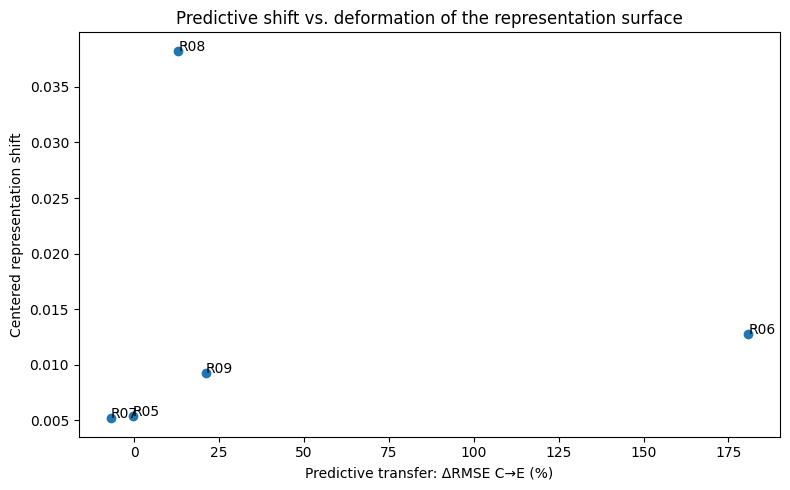

In [10]:
fig,ax = plt.subplots(
    figsize=(8,5)
)

ax.scatter(
    principal["delta_RMSE_pct"],
    principal["centered_representation_shift_ref"]
)

for r in principal.itertuples(index=False):
    ax.annotate(
        r.replication,
        (
            r.delta_RMSE_pct,
            r.centered_representation_shift_ref
        )
    )

ax.set_xlabel(
    "Predictive transfer: ΔRMSE C→E (%)"
)

ax.set_ylabel(
    "Centered representation shift"
)

ax.set_title(
    "Predictive shift vs. deformation of the representation surface"
)

plt.tight_layout()

fig.savefig(
    OUT/"predictive_vs_centered_representation_shift.png",
    dpi=180
)

plt.show()

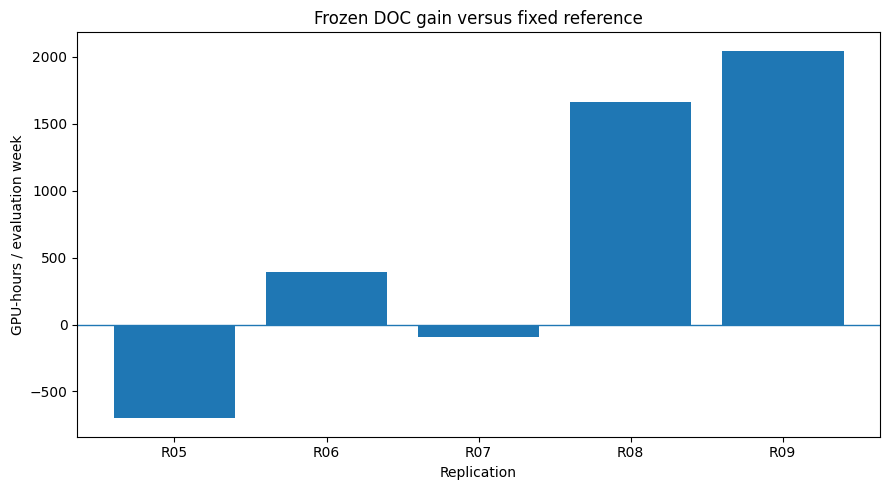

In [11]:
fig,ax = plt.subplots(
    figsize=(9,5)
)

ax.axhline(
    0,
    linewidth=1
)

ax.bar(
    principal["replication"],
    principal["gain_vs_reference_GPU_hours"]
)

ax.set_xlabel(
    "Replication"
)

ax.set_ylabel(
    "GPU-hours / evaluation week"
)

ax.set_title(
    "Frozen DOC gain versus fixed reference"
)

plt.tight_layout()

fig.savefig(
    OUT/"frozen_gain_GPU_hours.png",
    dpi=180
)

plt.show()

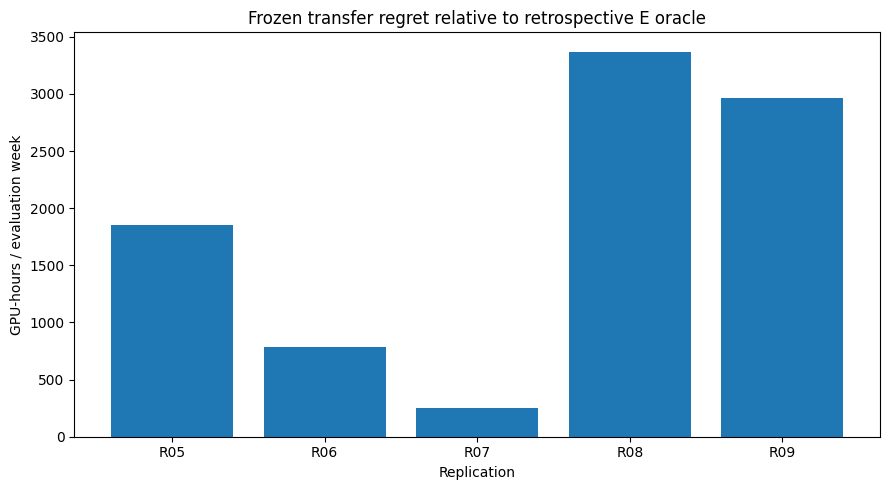

In [12]:
fig,ax = plt.subplots(
    figsize=(9,5)
)

ax.bar(
    principal["replication"],
    principal["transfer_regret_GPU_hours"]
)

ax.set_xlabel(
    "Replication"
)

ax.set_ylabel(
    "GPU-hours / evaluation week"
)

ax.set_title(
    "Frozen transfer regret relative to retrospective E oracle"
)

plt.tight_layout()

fig.savefig(
    OUT/"transfer_regret_GPU_hours.png",
    dpi=180
)

plt.show()

In [13]:
zip_out = ROOT/"outputs_fame_gpu_04c.zip"

with zipfile.ZipFile(
    zip_out,
    "w",
    compression=zipfile.ZIP_DEFLATED
) as z:
    for p in OUT.rglob("*"):
        if p.is_file():
            z.write(
                p,
                arcname=f"outputs_fame_gpu_04c/{p.name}"
            )

print("ZIP criado:",zip_out.resolve())
print("Envie outputs_fame_gpu_04c.zip.")

ZIP criado: C:\Users\tiago\Dropbox\Artigos\FAME\FAME\Artigo 2 - AOR\FAME_GPU\outputs_fame_gpu_04c.zip
Envie outputs_fame_gpu_04c.zip.
